In [2]:
# importing necessary modules that will be used in our script
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

I0000 00:00:1791616002.788351   10648 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791616009.745231   10648 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791616017.869894   10648 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [20]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANEL = 3
EPOCHS = 50

In [5]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../training_dataset", # directory of your source dataset
    shuffle=True, #randomly shuffling images
    image_size = (IMAGE_SIZE, IMAGE_SIZE), # resize all images to have same dimensions
    batch_size = BATCH_SIZE # load 32 image for each batch
)

Found 2152 files belonging to 3 classes.


E0000 00:00:1791616524.895991   10648 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [6]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [7]:
len(dataset) # it runned 68 batches nd for every batch it is loading 32 image so 68 * 32 is 2176

68

In [9]:
for batch_image, label_batch in dataset.take(1):
    print(batch_image.shape)
    print(label_batch.numpy())
    # 0 is Potato___Early_blight, 1 is Potato___Late_blight and 2 is Potato___healthy just like array of our class_names

(32, 256, 256, 3)
[1 1 1 0 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 2 2 1 0 0 1 1 1 1 0 1 2 0]


W0000 00:00:1791616928.494229   15304 cpu_allocator_impl.cc:82] Allocation of 25165824 exceeds 10% of free system memory.
W0000 00:00:1791616928.530944   15306 cpu_allocator_impl.cc:82] Allocation of 25165824 exceeds 10% of free system memory.


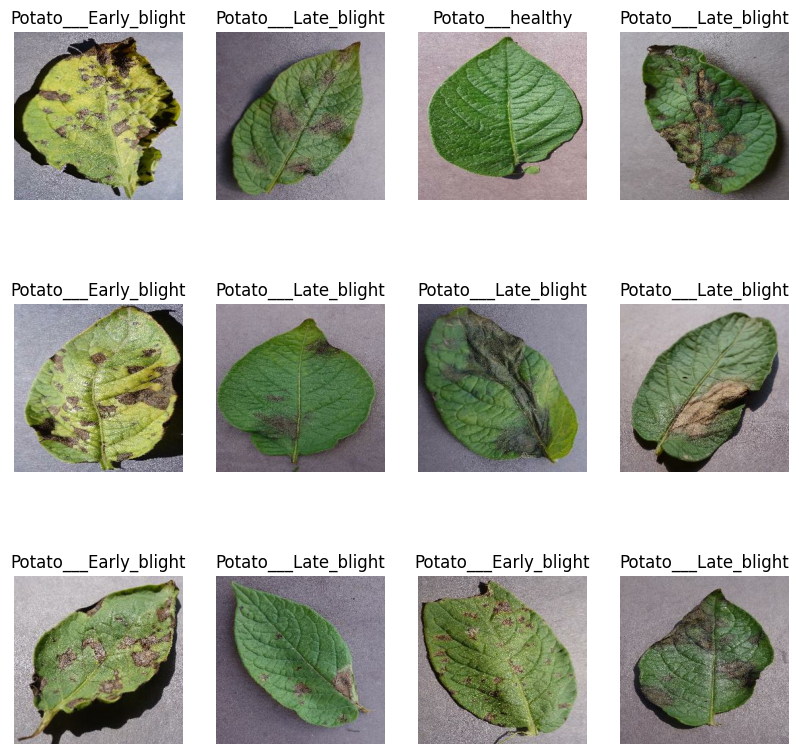

In [19]:
plt.figure(figsize=(10, 10))
for batch_image, label_batch in dataset.take(1):
    for i in range(12):
            #  i + 1 means space to be added btn the images, and 3 means three rows , 4 columns
            ax = plt.subplot(3, 4, i + 1)
            plt.axis("off") # hidding x axis numbers an y-axis numbers
            plt.imshow(batch_image[i].numpy().astype("uint8"))
            plt.title(class_names[label_batch[i]])
            # print(batch_image[0].numpy())

In [ ]:
# BIG OVERVIEW
80% ==> training
20% ==> 10% validation, 10% test

In [21]:
training_size = 0.8
len(dataset)*training_size

54.400000000000006

In [22]:
training_ds = dataset.take(54)

In [23]:
test_ds = dataset.skip(54)
len(test_ds)

14

In [25]:
validation = 0.1
len(dataset)*validation

6.800000000000001

In [26]:
validation_ds = test_ds.take(6)

In [28]:
test_ds = test_ds.skip(6)